## Import relevant libraries

In [13]:
from pathlib import Path
import ezdxf
from collections import Counter
import pandas as pd
from helpers import *

## Find all different entity-types in the DXF-dataset + count

In [14]:
total = Counter()
for f in Path("../Challenge1/10991360").glob("*.[dD][xX][fF]"): 
    try:
        msp = ezdxf.readfile(f).modelspace()
        total.update(e.dxftype() for e in msp)
    except Exception as ex:
        print(f"Fehler bei {f.name}: {ex}")

print(total)

Counter({'LINE': 1814, 'CIRCLE': 530, 'ARC': 491, 'POINT': 63})


-> Objects of type "Line", "Circle" and "Arc" have to be taken into account for the DXF functions (LWPOLYLINE and POLYLINE are not relevant for this dataset). What's the function of "Points"? (Since they are not part of the cutting geometry maybe some kind of marker?).

## Get entity-types of all DXF files containing "Points"

In [15]:
for f in Path("../Challenge1/10991360").glob("*.[dD][xX][fF]"):
    msp = ezdxf.readfile(f).modelspace()
    c = Counter(e.dxftype() for e in msp)
    if c["POINT"]:
        print(f.name, dict(c))

Geo (23).DXF {'ARC': 18, 'LINE': 52, 'POINT': 6}
Geo (9).DXF {'ARC': 10, 'CIRCLE': 4, 'LINE': 16, 'POINT': 2}
Geo (78).DXF {'ARC': 6, 'CIRCLE': 51, 'LINE': 11, 'POINT': 1}
Geo (14).DXF {'ARC': 27, 'LINE': 38, 'POINT': 2}
Geo (13).DXF {'ARC': 6, 'CIRCLE': 2, 'LINE': 13, 'POINT': 1}
Geo (25).DXF {'ARC': 27, 'CIRCLE': 5, 'LINE': 30, 'POINT': 5}
Geo (64).DXF {'CIRCLE': 8, 'ARC': 8, 'LINE': 102, 'POINT': 4}
Geo (65).DXF {'ARC': 22, 'LINE': 34, 'POINT': 10}
Geo (53).DXF {'CIRCLE': 6, 'ARC': 4, 'LINE': 41, 'POINT': 1}
Geo (12).DXF {'CIRCLE': 9, 'ARC': 4, 'LINE': 16, 'POINT': 2}
Geo (11).DXF {'ARC': 32, 'LINE': 42, 'POINT': 6}
Geo (66).DXF {'ARC': 20, 'LINE': 35, 'POINT': 7}
Geo (71).DXF {'CIRCLE': 1, 'ARC': 3, 'LINE': 10, 'POINT': 1}
Geo (10).DXF {'ARC': 14, 'LINE': 25, 'POINT': 5}
Geo (7).DXF {'ARC': 6, 'LINE': 13, 'POINT': 3}
Geo (57).DXF {'CIRCLE': 6, 'ARC': 44, 'LINE': 87, 'POINT': 5}
Geo (6).DXF {'ARC': 12, 'CIRCLE': 2, 'LINE': 25, 'POINT': 2}


## Test if POINTS are markers for centers of circles
test for 3 random DXF files

In [16]:
for name in ["10991360/Geo (65).DXF", "10991360/Geo (78).DXF", "10991360/Geo (13).DXF"]:
    msp = ezdxf.readfile(name).modelspace()
    circles = [(c.dxf.center.x, c.dxf.center.y) for c in msp.query("CIRCLE")]
    print(name)
    for p in msp.query("POINT"):
        x, y = p.dxf.location.x, p.dxf.location.y
        d = min((((x - cx)**2 + (y - cy)**2) ** 0.5 for cx, cy in circles), default=None)
        print(f"  layer={p.dxf.layer} pos=({x:.2f}, {y:.2f}) Abstand zum nächsten Kreismittelpunkt: {d}")

10991360/Geo (65).DXF
  layer=0 pos=(39.70, 65.75) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(116.85, 71.85) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(212.48, 78.22) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(310.47, 67.81) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(391.05, 61.55) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(487.54, 54.74) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(576.94, 64.46) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(697.71, 62.75) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(752.72, 75.29) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(815.90, 62.79) Abstand zum nächsten Kreismittelpunkt: None
10991360/Geo (78).DXF
  layer=0 pos=(351.03, 143.89) Abstand zum nächsten Kreismittelpunkt: 48.770753046099905
10991360/Geo (13).DXF
  layer=0 pos=(88.11, 22.88) Abstand zum nächsten Kreismittelpunkt: 71.70466060645266


 -> Points are on the same layer as everything else and are not markers for centers of circles (Geo 63: no circles but still 10 Points)

## Plot the analysed DXF files

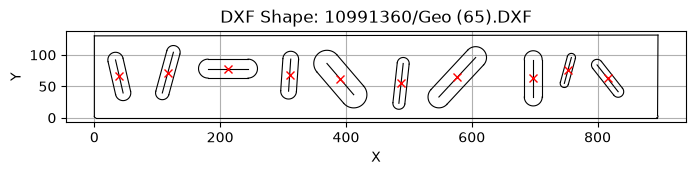

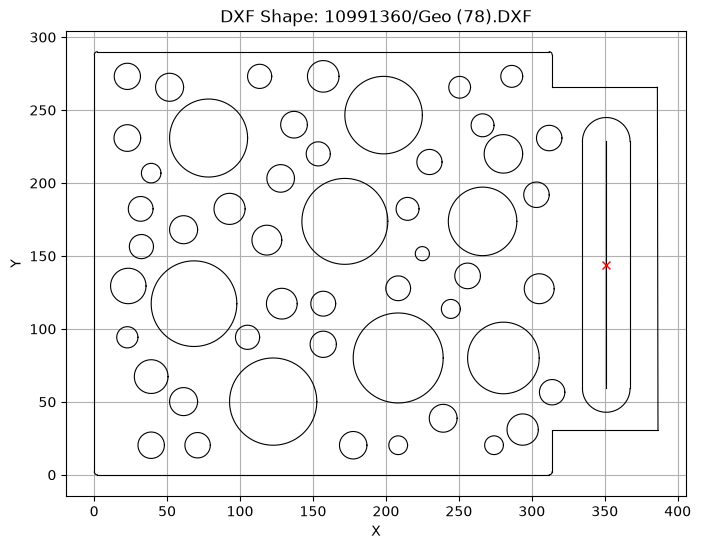

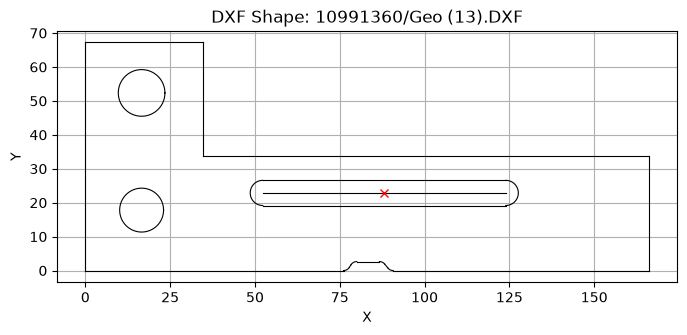

In [17]:
plot_dxf("10991360/Geo (65).DXF")
plot_dxf("10991360/Geo (78).DXF")
plot_dxf("10991360/Geo (13).DXF")

## Point location
#### Test for all DXF files containing "Points" in which layer their points are located

In [18]:
for f in Path("../Challenge1/10991360").glob("*.[dD][xX][fF]"):
    points = get_point_context(f)                       
    lines = get_line_context(f) 
    if points or lines:
            flag = "" if len(points) == len(lines) else "   <-- Anzahl verschieden"
            print(f.name, "| POINTs:", points, "| unconnected LINEs:", lines, flag)


Geo (23).DXF | POINTs: [1, 1, 1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1, 1, 1] 
Geo (9).DXF | POINTs: [1, 1] | unconnected LINEs: [1, 1] 
Geo (78).DXF | POINTs: [1] | unconnected LINEs: [1] 
Geo (14).DXF | POINTs: [1, 1] | unconnected LINEs: [1, 1] 
Geo (13).DXF | POINTs: [1] | unconnected LINEs: [1] 
Geo (25).DXF | POINTs: [1, 1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1, 1] 
Geo (64).DXF | POINTs: [1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1] 
Geo (65).DXF | POINTs: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1] 
Geo (53).DXF | POINTs: [1] | unconnected LINEs: [1] 
Geo (12).DXF | POINTs: [1, 1] | unconnected LINEs: [1, 1] 
Geo (11).DXF | POINTs: [1, 1, 1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1, 1, 1] 
Geo (66).DXF | POINTs: [1, 1, 1, 1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1, 1, 1, 1] 
Geo (71).DXF | POINTs: [1] | unconnected LINEs: [1] 
Geo (10).DXF | POINTs: [1, 1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1, 1] 
Geo (7).DXF | POINTs: [1,

-> all points and lines are located in "scrap"-layers (layer 1)

-> Together with the three plotted DXF-files it's quite clear that "Points" and "unconnected LINEs" are markers for centers of ovals. Taking a closer look on the output we can also observe that the number of POINTs and unconnected LINEs is the same for each file.

For the helper functions and the further EDA this has the following consequences: "Points" are irrelevant for any calculation of cutting length, bounding box or number of holes. "Unconnected lines" (Meaning lines which are not connected to any ARCs, CIRCLEs or other LINEs) are also irrelevant for the cutting process (since they'll be removed with the scrap) and therefore should NOT be taken into account when calculating cutting length.